# 01. Data Understanding & Source Provenance: ICNF SGIF National Database


In [1]:
# Import standard library for path manipulation and operating system interactions
import os

# Import core scientific, data manipulation, and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define relative path to the extracted raw ICNF SGIF dataset
# Using self-contained relative paths ensures full reproducibility and portability
data_directory = os.path.join("Dataset", "icnf_sgif", "extracted")

# Configure pandas display options for clean and readable tabular outputs
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Environment configured successfully.")
print(f"Base data directory: {data_directory}")


Environment configured successfully.
Base data directory: Dataset\icnf_sgif\extracted


## Section 1: Discovering and Cataloging Raw Excel Workbooks


In [2]:
# Initialize an empty list to store the paths of discovered Excel workbooks
excel_files = []

# Walk through the extracted dataset directory to locate all Excel files
for root_directory, sub_directories, file_names in os.walk(data_directory):
    for file_name in file_names:
        # Select .xlsx files while ignoring temporary lock files (e.g., ~$file.xlsx)
        if file_name.endswith(".xlsx") and not file_name.startswith("~$"):
            full_file_path = os.path.join(root_directory, file_name)
            excel_files.append(full_file_path)

# Sort files alphabetically to ensure consistent chronological order (2001-2010, 2011-2020, 2021-2025)
excel_files.sort()

print("Discovered ICNF SGIF National Fire Workbooks:")
print("-" * 80)

# Display workbook filename and size in megabytes (MB)
for file_path in excel_files:
    file_size_bytes = os.path.getsize(file_path)
    file_size_mb = file_size_bytes / (1024 * 1024)
    file_name = os.path.basename(file_path)
    print(f"Workbook: {file_name:<42} | Size: {file_size_mb:.2f} MB")

print("-" * 80)
print(f"Total workbooks located: {len(excel_files)}")


Discovered ICNF SGIF National Fire Workbooks:
--------------------------------------------------------------------------------
Workbook: Registos_Incendios_SGIF_2001_2010.xlsx     | Size: 83.17 MB
Workbook: Registos_Incendios_SGIF_2011_2020.xlsx     | Size: 59.08 MB
Workbook: Registos_Incendios_SGIF_2021_2025.xlsx     | Size: 13.86 MB
--------------------------------------------------------------------------------
Total workbooks located: 3


## Section 2: Inspecting National Record Counts and Column Schemas

In [3]:
# Dictionary to hold preview sample DataFrames for each decadal workbook
samples_by_workbook = {}

# Official national record counts established by ICNF publication metadata
national_record_counts = {
    "Registos_Incendios_SGIF_2001_2010.xlsx": 279743,
    "Registos_Incendios_SGIF_2011_2020.xlsx": 177129,
    "Registos_Incendios_SGIF_2021_2025.xlsx": 40606
}

# Read a 100-row preview from each workbook
for file_path in excel_files:
    file_name = os.path.basename(file_path)
    print(f"Loading preview (100 rows) from: {file_name}...")
    preview_df = pd.read_excel(file_path, nrows=100)
    samples_by_workbook[file_name] = preview_df

print("\nSchema Uniformity and Record Count Verification:")
print("-" * 85)

# Verify whether all three workbooks share identical column names in identical order
schemas_are_identical = True
first_schema_columns = None

for file_name, preview_df in samples_by_workbook.items():
    column_count = len(preview_df.columns)
    recorded_total = national_record_counts.get(file_name, 0)
    
    if first_schema_columns is None:
        first_schema_columns = list(preview_df.columns)
    else:
        if list(preview_df.columns) != first_schema_columns:
            schemas_are_identical = False
            
    print(f"{file_name:<42} | Columns: {column_count} | National Records: {recorded_total:,}")

print("-" * 85)
combined_records = sum(national_record_counts.values())
print(f"Combined National Fire Records (2001-2025): {combined_records:,}")
print(f"Shared Column Count Across All Workbooks:   {len(first_schema_columns)}")
print(f"Schemas Identical Across All Three Decades:  {schemas_are_identical}")


Loading preview (100 rows) from: Registos_Incendios_SGIF_2001_2010.xlsx...
Loading preview (100 rows) from: Registos_Incendios_SGIF_2011_2020.xlsx...
Loading preview (100 rows) from: Registos_Incendios_SGIF_2021_2025.xlsx...

Schema Uniformity and Record Count Verification:
-------------------------------------------------------------------------------------
Registos_Incendios_SGIF_2001_2010.xlsx     | Columns: 41 | National Records: 279,743
Registos_Incendios_SGIF_2011_2020.xlsx     | Columns: 41 | National Records: 177,129
Registos_Incendios_SGIF_2021_2025.xlsx     | Columns: 41 | National Records: 40,606
-------------------------------------------------------------------------------------
Combined National Fire Records (2001-2025): 497,478
Shared Column Count Across All Workbooks:   41
Schemas Identical Across All Three Decades:  True


### Visualization 1: National Fire Record Volume by Decade


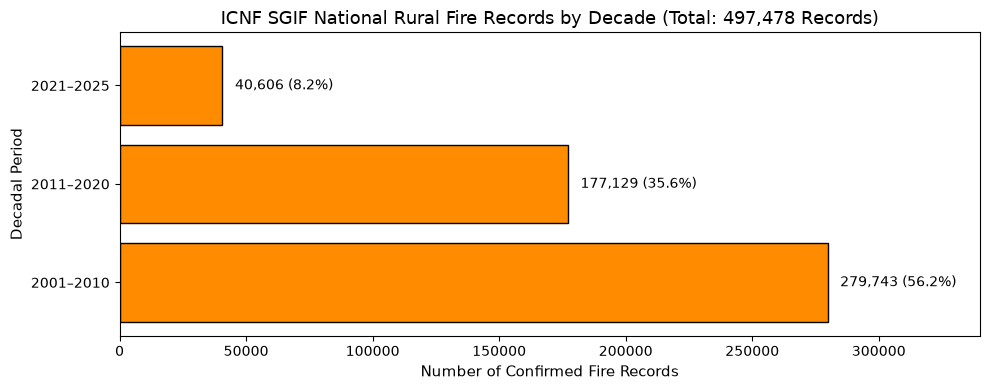

In [4]:
# Define workbook decadal labels and their corresponding official record counts
decades = ["2001–2010", "2011–2020", "2021–2025"]
record_counts = [279743, 177129, 40606]
total_records = sum(record_counts)

# Create a clean horizontal bar chart
plt.figure(figsize=(10, 4))
plt.barh(decades, record_counts, color="darkorange", edgecolor="black")

plt.title(f"ICNF SGIF National Rural Fire Records by Decade (Total: {total_records:,} Records)", fontsize=13)
plt.xlabel("Number of Confirmed Fire Records", fontsize=11)
plt.ylabel("Decadal Period", fontsize=11)

# Annotate each bar with its exact record count and percentage
for index, count in enumerate(record_counts):
    percentage = (count / total_records) * 100.0
    plt.text(count + 5000, index, f"{count:,} ({percentage:.1f}%)", va="center", fontsize=10)

plt.xlim(0, 340000)
plt.tight_layout()
plt.show()


## Section 3: Rigorous Column Classification & Target Leakage Prevention Audit


In [5]:
# Access the first preview DataFrame directly by its dictionary key
preview_df = samples_by_workbook["Registos_Incendios_SGIF_2001_2010.xlsx"]

# 1. Print raw columns visibly so the reader sees all 41 fields loaded from the Excel file
print("Raw Portuguese Columns from SGIF Register (Total: 41 Columns):")
print("-" * 80)
print(preview_df.columns.tolist())
print("-" * 80)

# 2. Categorize the columns using three clear, readable Python lists
target_columns = [
    "AreaTotal_ha", 
    "AreaPov_ha", 
    "AreaMato_ha", 
    "AreaAgric_ha", 
    "ClasseArea"
]

leakage_columns = [
    "DataHora_PrimeiraIntervencao", 
    "DataHora_Extincao", 
    "Duracao_Horas", 
    "IncSup24horas", 
    "CodCausa", 
    "TipoCausa", 
    "GrupoCausa", 
    "DescricaoCausa"
]

eligible_columns = [
    col for col in preview_df.columns 
    if col not in target_columns and col not in leakage_columns
]

# 3. Build the audit summary table dynamically from these lists
audit_rows = []

for column_name in target_columns:
    audit_rows.append({
        "Column": column_name,
        "Data_Type": str(preview_df[column_name].dtype),
        "Category": "Target Ground Truth",
        "Availability": "Post-Ignition",
        "Eligible": "No (Target / Component)"
    })

for column_name in leakage_columns:
    audit_rows.append({
        "Column": column_name,
        "Data_Type": str(preview_df[column_name].dtype),
        "Category": "Forbidden Target Leakage",
        "Availability": "Post-Ignition / Post-Extinction",
        "Eligible": "No (Strict Leakage)"
    })

for column_name in eligible_columns:
    audit_rows.append({
        "Column": column_name,
        "Data_Type": str(preview_df[column_name].dtype),
        "Category": "Eligible Predictors",
        "Availability": "Alert Time",
        "Eligible": "Yes (Prediction-Time)"
    })

audit_summary_df = pd.DataFrame(audit_rows)

print("\nTarget Leakage Prevention Audit - Column Counts by Category:")
print("=" * 80)
category_counts = audit_summary_df["Category"].value_counts()
print(category_counts.to_string())
print(f"Total Columns Audited: {len(audit_summary_df)}")
print("=" * 80)

print("\nSample of Audited Columns (First 15 Rows):")
print(audit_summary_df.head(15).to_string(index=False))


Raw Portuguese Columns from SGIF Register (Total: 41 Columns):
--------------------------------------------------------------------------------
['Codigo_SGIF', 'Codigo_ANEPC', 'Ano', 'Mes', 'Dia', 'Hora', 'AreaPov_ha', 'AreaMato_ha', 'AreaAgric_ha', 'AreaTotal_ha', 'ClasseArea', 'DataHoraAlerta', 'DataHora_PrimeiraIntervencao', 'DataHora_Extincao', 'Duracao_Horas', 'IncSup24horas', 'DTCCFR', 'Distrito', 'Concelho', 'Freguesia', 'Local', 'RNAP', 'RNMPF', 'X_Militar', 'Y_Militar', 'Latitude', 'Longitude', 'X_ETRS89', 'Y_ETRS89', 'DSR', 'FWI', 'ISI', 'DC', 'DMC', 'FFMC', 'BUI', 'CodCausa', 'TipoCausa', 'GrupoCausa', 'DescricaoCausa', 'FonteAlerta']
--------------------------------------------------------------------------------

Target Leakage Prevention Audit - Column Counts by Category:
Category
Eligible Predictors         28
Forbidden Target Leakage     8
Target Ground Truth          5
Total Columns Audited: 41

Sample of Audited Columns (First 15 Rows):
                      Column   

### Visualization 2: Target Leakage Prevention Audit Breakdown

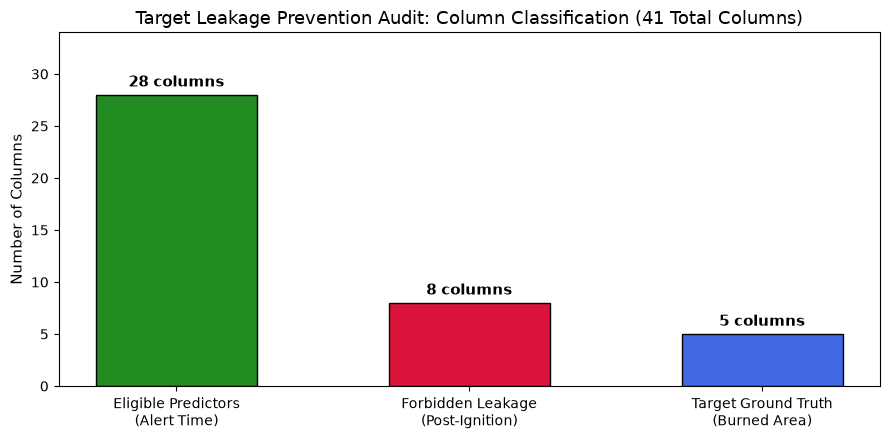

In [6]:
# Define categories, counts, and distinct colors for visualization
categories = [
    "Eligible Predictors\n(Alert Time)", 
    "Forbidden Leakage\n(Post-Ignition)", 
    "Target Ground Truth\n(Burned Area)"
]
counts = [len(eligible_columns), len(leakage_columns), len(target_columns)]
bar_colors = ["forestgreen", "crimson", "royalblue"]

# Create a clean vertical bar chart
plt.figure(figsize=(9, 4.5))
bars = plt.bar(categories, counts, color=bar_colors, edgecolor="black", width=0.55)

plt.title("Target Leakage Prevention Audit: Column Classification (41 Total Columns)", fontsize=13)
plt.ylabel("Number of Columns", fontsize=11)
plt.ylim(0, 34)

# Annotate each bar with its exact column count
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.8, f"{int(height)} columns", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


## Section 4: Initial Inspection of the Target Variable (`AreaTotal_ha`)


In [7]:
# Collect the AreaTotal_ha column from all three preview samples
burned_area_samples = []

for workbook_name, preview_df in samples_by_workbook.items():
    if "AreaTotal_ha" in preview_df.columns:
        burned_area_samples.append(preview_df["AreaTotal_ha"])

# Concatenate into a single pandas Series
all_sampled_areas = pd.concat(burned_area_samples, ignore_index=True)

# Calculate core summary statistics
total_sample_count = len(all_sampled_areas)
micro_fire_count = int((all_sampled_areas == 0.0).sum())
micro_fire_percentage = (micro_fire_count / total_sample_count) * 100.0

minimum_area = float(all_sampled_areas.min())
first_quartile = float(all_sampled_areas.quantile(0.25))
median_area = float(all_sampled_areas.median())
mean_area = float(all_sampled_areas.mean())
third_quartile = float(all_sampled_areas.quantile(0.75))
maximum_area = float(all_sampled_areas.max())

print("Summary Statistics for Burned Area (AreaTotal_ha) Across Preview Samples:")
print("-" * 80)
print(f"Total Sampled Fire Events:          {total_sample_count}")
print(f"Micro-Fires (< 0.01 ha recorded):   {micro_fire_count} ({micro_fire_percentage:.1f}%)")
print(f"Minimum Burned Area:                {minimum_area:.4f} ha")
print(f"25th Percentile (Q1):               {first_quartile:.4f} ha")
print(f"Median Burned Area (Q2):            {median_area:.4f} ha")
print(f"Mean Burned Area:                   {mean_area:.4f} ha")
print(f"75th Percentile (Q3):               {third_quartile:.4f} ha")
print(f"Maximum Burned Area:                {maximum_area:.4f} ha")
print("-" * 80)

# Quantify positive skewness using the ratio of mean to median
mean_to_median_ratio = mean_area / (median_area if median_area > 0 else 0.001)
print(f"Mean-to-Median Ratio:               {mean_to_median_ratio:.2f}x")
print("\nAnalytical Conclusion:")
print("The mean is substantially larger than the median, demonstrating intense")
print("right-skewness. This confirms that burned area cannot be modeled effectively")
print("with standard linear assumptions without logarithmic or power transformations.")


Summary Statistics for Burned Area (AreaTotal_ha) Across Preview Samples:
--------------------------------------------------------------------------------
Total Sampled Fire Events:          300
Micro-Fires (< 0.01 ha recorded):   5 (1.7%)
Minimum Burned Area:                0.0000 ha
25th Percentile (Q1):               0.0100 ha
Median Burned Area (Q2):            0.1000 ha
Mean Burned Area:                   3.2547 ha
75th Percentile (Q3):               1.0000 ha
Maximum Burned Area:                154.7946 ha
--------------------------------------------------------------------------------
Mean-to-Median Ratio:               32.55x

Analytical Conclusion:
The mean is substantially larger than the median, demonstrating intense
right-skewness. This confirms that burned area cannot be modeled effectively
with standard linear assumptions without logarithmic or power transformations.


### Visualization 3: Distribution Comparison — Raw vs. Log-Transformed Area

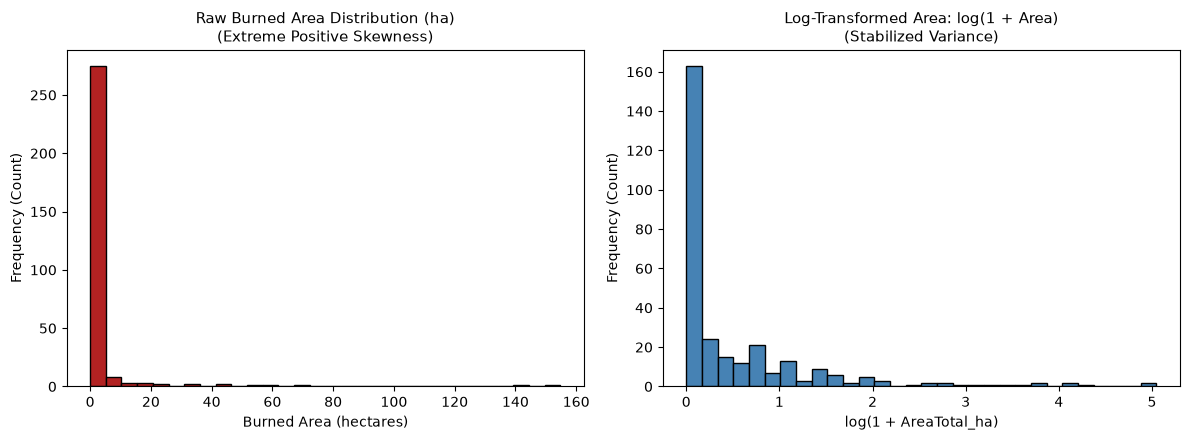

In [8]:
# Create a side-by-side figure to compare raw and transformed distributions
plt.figure(figsize=(12, 4.5))

# Left Subplot: Raw linear burned area (ha)
plt.subplot(1, 2, 1)
plt.hist(all_sampled_areas, bins=30, color="firebrick", edgecolor="black")
plt.title("Raw Burned Area Distribution (ha)\n(Extreme Positive Skewness)", fontsize=11)
plt.xlabel("Burned Area (hectares)", fontsize=10)
plt.ylabel("Frequency (Count)", fontsize=10)

# Right Subplot: Log-transformed burned area log(1 + area)
log_transformed_areas = np.log1p(all_sampled_areas)
plt.subplot(1, 2, 2)
plt.hist(log_transformed_areas, bins=30, color="steelblue", edgecolor="black")
plt.title("Log-Transformed Area: log(1 + Area)\n(Stabilized Variance)", fontsize=11)
plt.xlabel("log(1 + AreaTotal_ha)", fontsize=10)
plt.ylabel("Frequency (Count)", fontsize=10)

plt.tight_layout()
plt.show()
